# Predetermined Sequence Twin-Crane Scheduling with Rehandle Assignment

원본 `Reha_Crane.ipynb` 를 복사해 수정한 버전.

**바뀐 점**
1. **작업 순서 고정 (Predetermined Sequence)** : 크레인별 작업 순서를 입력으로 받음 → 본 작업끼리의 순서 변수 $y$ 와 관련 제약 제거
2. **본 작업 할당 고정** : non-crossing 때문에 DS·LD → Seaside(SC), GI·GO → Landside(LC) 로 자동 할당 → 본 작업의 $x$ 제거
3. **의사결정 = Rehandle 을 누가 하느냐** : LD·GO 에 딸린 rehandle $r$ 마다 $x_{rv}$
4. 해측 TP(Bay 0) / 육측 TP(Bay N+1) 도입, rehandle 목적 Bay 지정 가능
5. 크레인 간 간섭 순서 $z$ 는 유지 (순서가 고정돼도 두 크레인 중 누가 먼저 간섭 구간을 지나갈지는 결정해야 함)
6. 트럭 대기를 모든 트럭(DS·LD 내부, GI·GO 외부)으로 정의하고 목적함수 `OBJ="truck_wait"` 추가
- 2026-10-06 · 시각화 셀: t̂·pick·drop 이 소수여도(실데이터 초 단위, t̂=1.5) 그려지도록 시간 반올림 · 이동 속도 1/t̂ 반영 (모델 변경 없음)

**toy 결과** (makespan / Σ 트럭 대기 / 내부 DS·LD / 외부 GI·GO)
- 비교군 : 189 / 1074 / 347 / 727
- 협업, `OBJ="makespan"` : 163 / 1136 / 515 / 621 → GO 는 좋아지지만 SC 가 지원하느라 자기 트럭을 기다리게 해 전체는 나빠짐
- 협업, `OBJ="truck_wait"` : 174 / 1047 / 371 / 676 → 전체 트럭 대기 −2.5 %, makespan −7.9 %

**변경 이력**
- 2026-10-01 · 순서·할당 고정, rehandle 할당 $x_{rv}$, 해측/육측 TP, `ALLOW_ASSIST` · `HOME_RH_FIXED` 옵션
- 2026-10-01 · 트럭 대기를 GO 만이 아니라 모든 트럭(DS·LD·GI·GO)으로 확장, `OBJ="truck_wait"` 추가
- 2026-10-13 · `RH_AFTER_ARRIVAL` 옵션: True 면 rehandle 은 그 본 작업의 트럭이 도착한 뒤에만 시작 ($a_r = a_{j(r)}$, 실기록 반출 rehandle 99.8 % 가 요청 뒤 시작). 기본 False 는 예전과 같음 ($a_r=0$, 트럭이 오기 전에 미리 치울 수 있음). 웹 협업 모델·휴리스틱은 기본 True
- 2026-10-28 · `LD_LOOKAHEAD` 옵션: 적하(LD) rehandle 은 AGV 도착을 H 초 전부터 안다고 보고 $a_r=\max(0,a_j-H)$ (반출 GO 는 외부트럭 도착을 모르므로 `RH_AFTER_ARRIVAL` 그대로). 기본 None = 예전과 같음. 선행연구 Park et al.(2010) 의 실시간 twin RMG 스케줄링 설정을 참고
- 2026-10-28 · `CRANE_READY` (크레인이 비는 시각, 제약 (4) $s_i \ge \text{ready}_v + \tau^0_{vi}$): 롤링 호라이즌 실험에서 하던 작업이 끝나는 시각을 넣기 위한 것. 기본 0 = 예전과 같음



### Data (Predetermined Sequence)

In [1]:
# =========================================================
# 1. 블록 / 크레인 / 작업 데이터 입력
# =========================================================
# Bay 좌표: 0 = 해측 TP(Sea TP), 1~N_BAY = 야드 Bay, N_BAY+1 = 육측 TP(Land TP)
N_BAY   = 30
SEA_TP  = 0
LAND_TP = N_BAY + 1
Bay = list(range(SEA_TP, LAND_TP + 1))

# SC = Seaside crane(해측, 홀수호기), LC = Landside crane(육측, 짝수호기)
Crane = {
    "SC": {"initial": SEA_TP},
    "LC": {"initial": LAND_TP},
}

# 작업 타입 -> 담당 크레인 (non-crossing 때문에 자동 결정)
TYPE_CRANE = {"DS": "SC", "LD": "SC", "GI": "LC", "GO": "LC"}

# ---------------------------------------------------------
# Predetermined Sequence
#   크레인별로 아래 dict 에 "적힌 순서" 가 곧 고정된 작업 순서
#   bay  : 야드 내 작업 Bay
#   r_c  : Rehandle 개수 (LD, GO 만 해당)
#   rh_d : (선택) Rehandle 별 목적 Bay 리스트. 없으면 제자리(같은 Bay) rehandle
#   a    : (선택) 작업 가능 시각 (GO = 트럭 도착 시각 등). 없으면 0
# ---------------------------------------------------------
Seq_SC = {
    "DS_1": {"type": "DS", "bay": 20},
    "LD_1": {"type": "LD", "bay": 8,  "r_c": 1},
    "DS_2": {"type": "DS", "bay": 10},
    "LD_2": {"type": "LD", "bay": 15, "r_c": 2, "rh_d": [15, 13]},
    "DS_3": {"type": "DS", "bay": 6},
}

Seq_LC = {
    "GO_1": {"type": "GO", "bay": 14, "r_c": 3, "a": 0},
    "GI_1": {"type": "GI", "bay": 22},
    "GO_2": {"type": "GO", "bay": 16, "r_c": 3, "rh_d": [16, 16, 19], "a": 10},
    "GO_3": {"type": "GO", "bay": 12, "r_c": 2, "a": 20},
    "GI_2": {"type": "GI", "bay": 26},
    "GO_4": {"type": "GO", "bay": 18, "r_c": 2, "a": 30},
    "GO_5": {"type": "GO", "bay": 25, "r_c": 0, "a": 40},
}

Sequence = {"SC": list(Seq_SC.keys()), "LC": list(Seq_LC.keys())}
Main_Jobs = {**Seq_SC, **Seq_LC}

# 타입과 크레인이 맞는지 확인
for v, seq in Sequence.items():
    for j in seq:
        assert TYPE_CRANE[Main_Jobs[j]["type"]] == v, f"{j} 는 {v} 의 작업이 아님"

### Tasks

In [2]:
# =========================================================
# 2. Tasks 생성 (본 작업 + Rehandle 작업)
# =========================================================
# 본 작업 (o, d) : TP 위치는 작업 타입으로 결정
#   DS : 해측 TP -> 야드 Bay      LD : 야드 Bay -> 해측 TP
#   GI : 육측 TP -> 야드 Bay      GO : 야드 Bay -> 육측 TP
def od_of(job):
    t, b = job["type"], job["bay"]
    if t == "DS": return SEA_TP, b
    if t == "LD": return b, SEA_TP
    if t == "GI": return LAND_TP, b
    if t == "GO": return b, LAND_TP
    raise ValueError(t)

Tasks = {}
Precedence_Set = []   # (선행, 후행)
Set_M = []            # 본 작업 집합 (할당 고정)
Set_R = []            # Rehandle 작업 집합 (할당 = 의사결정)
home = {}             # 작업별 원래 담당 크레인
parent = {}           # Rehandle -> 본 작업

for v, seq in Sequence.items():
    for j in seq:
        job = Main_Jobs[j]
        o, d = od_of(job)
        Tasks[j] = {"o": o, "d": d, "a": job.get("a", 0), "type": job["type"]}
        Set_M.append(j)
        home[j] = v

        rc = job.get("r_c", 0)
        rh_d = job.get("rh_d", [job["bay"]] * rc)
        assert len(rh_d) == rc, f"{j}: rh_d 길이가 r_c 와 다름"
        prev = None
        for k in range(rc):
            r = f"{j}_r{k+1}"
            # rehandle: 본 작업 Bay 에서 집어 rh_d[k] Bay 에 내려놓음
            Tasks[r] = {"o": job["bay"], "d": rh_d[k], "a": 0, "type": "RH"}
            Set_R.append(r)
            home[r] = v
            parent[r] = j
            if prev is not None:
                Precedence_Set.append((prev, r))
            prev = r
        if prev is not None:
            Precedence_Set.append((prev, j))     # 마지막 rehandle -> 본 작업

print("[Main jobs]", Set_M)
print("[Rehandles]", Set_R)
print("[Precedence Set]", Precedence_Set)

[Main jobs] ['DS_1', 'LD_1', 'DS_2', 'LD_2', 'DS_3', 'GO_1', 'GI_1', 'GO_2', 'GO_3', 'GI_2', 'GO_4', 'GO_5']
[Rehandles] ['LD_1_r1', 'LD_2_r1', 'LD_2_r2', 'GO_1_r1', 'GO_1_r2', 'GO_1_r3', 'GO_2_r1', 'GO_2_r2', 'GO_2_r3', 'GO_3_r1', 'GO_3_r2', 'GO_4_r1', 'GO_4_r2']
[Precedence Set] [('LD_1_r1', 'LD_1'), ('LD_2_r1', 'LD_2_r2'), ('LD_2_r2', 'LD_2'), ('GO_1_r1', 'GO_1_r2'), ('GO_1_r2', 'GO_1_r3'), ('GO_1_r3', 'GO_1'), ('GO_2_r1', 'GO_2_r2'), ('GO_2_r2', 'GO_2_r3'), ('GO_2_r3', 'GO_2'), ('GO_3_r1', 'GO_3_r2'), ('GO_3_r2', 'GO_3'), ('GO_4_r1', 'GO_4_r2'), ('GO_4_r2', 'GO_4')]


### Parameter

In [3]:
# =========================================================
# 3. Parameter
# =========================================================
safety_margin = 1
t_hat = 1             # Bay 1칸 이동시간
pick = 1
drop = 1
Lambda = pick
h = pick + drop
rh_inplace = 3        # 같은 Bay 안에서 옮기는 rehandle 의 처리시간

ALLOW_ASSIST = True   # False 면 모든 rehandle 을 원래 크레인이 수행 (Baseline)
OBJ = "makespan"      # "makespan" / "truck_wait" (모든 트럭 대기 합) / "go_wait" (GO 트럭만)
HOME_RH_FIXED = True  # True 면 원래 크레인이 하는 rehandle 은 "직전 본 작업 이후 ~ 본 작업 전" 에만 수행
                      # (실제 운영처럼 본 작업 바로 앞에서 rehandle). False 면 원래 크레인도 미리 해둘 수 있음
RH_AFTER_ARRIVAL = False  # True 면 rehandle 은 그 본 작업의 트럭이 도착한 뒤(a_r = a_j)에만 시작 (실기록 99.8 %)
                          # False 면 a_r = 0 (트럭이 오기 전에 미리 치워 둘 수 있음)
                          # 반출(GO): 외부트럭(ET) 도착 시점을 미리 모른다고 보면 True
LD_LOOKAHEAD = None       # 적하(LD) rehandle: AGV·내부트럭 도착 시점을 H 초 전부터 안다고 볼 때 H (a_r = max(0, a_j - H))
                          # None 이면 LD 도 RH_AFTER_ARRIVAL 을 따름. 0 = 도착 뒤에만, 큰 값 = 언제든 미리

# 작업 처리시간
duration = {}
for i, td in Tasks.items():
    if td["type"] == "RH" and td["o"] == td["d"]:
        duration[i] = rh_inplace
    else:
        duration[i] = abs(td["o"] - td["d"]) * t_hat + h

# 작업 간 빈 이동시간 t_ij = |d_i - o_j|
travel_jobs = {(i, j): abs(Tasks[i]["d"] - Tasks[j]["o"]) * t_hat
               for i in Tasks for j in Tasks if i != j}

CRANE_READY = {"SC": 0, "LC": 0}   # 크레인이 비는 시각 (롤링 호라이즌: 하던 작업이 끝나는 시각). 보통 0
crane_initial = {v: Crane[v]["initial"] for v in Crane}
initial_CM = {(v, i): CRANE_READY.get(v, 0) + abs(crane_initial[v] - Tasks[i]["o"]) * t_hat
              for i in Tasks for v in Crane}

sort_crane = sorted(crane_initial.items(), key=lambda x: x[1])
crane_index = {k[0]: idx for idx, k in enumerate(sort_crane, start=1)}   # SC=1(아래), LC=2(위)

delta = {(v, w): (safety_margin + 1) * abs(crane_index[v] - crane_index[w])
         for v in Crane for w in Crane}

# 각 작업이 배정될 수 있는 크레인
#   본 작업 : 원래 크레인만 (고정)
#   Rehandle: 두 크레인 모두 (ALLOW_ASSIST=False 면 원래 크레인만)
cand = {}
for i in Tasks:
    if i in Set_R and ALLOW_ASSIST:
        cand[i] = list(Crane.keys())
    else:
        cand[i] = [home[i]]

# 시간창 / Big-M : 모든 작업을 한 크레인이 순서대로 해도 끝나는 시간으로 horizon 설정
horizon = (sum(duration.values())
           + max(Tasks[i]["a"] for i in Tasks) + max(CRANE_READY.values())
           + len(Tasks) * (LAND_TP - SEA_TP) * t_hat)
a = {i: Tasks[i]["a"] for i in Tasks}
for r in Set_R:
    _j = parent[r]
    if Tasks[_j]["type"] == "LD" and LD_LOOKAHEAD is not None:
        a[r] = max(0, Tasks[_j]["a"] - LD_LOOKAHEAD)   # AGV 도착을 H 초 전부터 앎 → 그만큼 미리 rehandle 가능
    elif RH_AFTER_ARRIVAL:
        a[r] = Tasks[_j]["a"]                          # 트럭 도착 뒤에만 (반출 ET 는 도착 전엔 모름)
b = {i: horizon for i in Tasks}
BigM = horizon

print("[Duration]", duration)
print("horizon / BigM =", horizon)

[Duration] {'DS_1': 22, 'LD_1': 10, 'LD_1_r1': 3, 'DS_2': 12, 'LD_2': 17, 'LD_2_r1': 3, 'LD_2_r2': 4, 'DS_3': 8, 'GO_1': 19, 'GO_1_r1': 3, 'GO_1_r2': 3, 'GO_1_r3': 3, 'GI_1': 11, 'GO_2': 17, 'GO_2_r1': 3, 'GO_2_r2': 3, 'GO_2_r3': 5, 'GO_3': 21, 'GO_3_r1': 3, 'GO_3_r2': 3, 'GI_2': 7, 'GO_4': 15, 'GO_4_r1': 3, 'GO_4_r2': 3, 'GO_5': 8}
horizon / BigM = 1024


### Set

In [4]:
# =========================================================
# 4. Set
# =========================================================
Set_T = list(Tasks.keys())
Set_V = list(Crane.keys())

# (1) 같은 크레인 위 "순서가 고정된" 연속 본 작업 쌍
Fixed_Seq_Pairs = []
for v, seq in Sequence.items():
    for k in range(len(seq) - 1):
        Fixed_Seq_Pairs.append((seq[k], seq[k + 1], v))

# (2) 순서를 결정해야 하는 쌍 : 둘 중 하나 이상이 Rehandle 이고 같은 크레인에 올 수 있는 쌍
#     (본 작업끼리는 순서가 고정이므로 제외)
Seq_Pairs = []   # (i, j) , i < j 한 번만
for idx_i, i in enumerate(Set_T):
    for j in Set_T[idx_i + 1:]:
        if i in Set_M and j in Set_M:
            continue
        if set(cand[i]) & set(cand[j]):
            Seq_Pairs.append((i, j))

# (3) 충돌 잠재쌍 Theta : 서로 다른 크레인에 올 수 있고, 작업 구간이 안전거리 안에서 겹치는 쌍
task_interval = {t: {"l_min": min(d["o"], d["d"]), "l_max": max(d["o"], d["d"])}
                 for t, d in Tasks.items()}

Theta = []
for t in Set_T:
    for tp in Set_T:
        if t == tp:
            continue
        for v in cand[t]:
            for w in cand[tp]:
                if v == w:
                    continue
                if crane_index[v] < crane_index[w]:          # v 아래, w 위
                    if task_interval[t]["l_max"] + delta[v, w] > task_interval[tp]["l_min"]:
                        Theta.append((t, tp, v, w))
                else:                                         # v 위, w 아래
                    if task_interval[t]["l_min"] - delta[v, w] < task_interval[tp]["l_max"]:
                        Theta.append((t, tp, v, w))

print("Fixed sequence pairs :", len(Fixed_Seq_Pairs))
print("Rehandle sequencing pairs :", len(Seq_Pairs))
print("Theta :", len(Theta))

Fixed sequence pairs : 10
Rehandle sequencing pairs : 234
Theta : 336


### ETD (Extend Temporal Distance)

In [5]:
# =========================================================
# 5. ETD (Extend Temporal Distance) - 원본과 동일
# =========================================================
def compute_etd_paper(t, tp, v, w, Tasks, delta, crane_index, t_hat, Lambda):
    l1_t  = Tasks[t]["o"]
    l2_t  = Tasks[t]["d"]
    l1_tp = Tasks[tp]["o"]
    l2_tp = Tasks[tp]["d"]
    d = delta[(v, w)]
    if crane_index[v] < crane_index[w]:
        base = (l2_t + d - l1_tp) * t_hat
        C11 = (l2_t + d > l1_tp)
        C12 = (l1_t + d > l1_tp)
        C13 = (l2_t + d > l2_tp)
        if C11:
            return base, "Case1-C1.1"
        elif C12 or C13:
            return base - Lambda, "Case1-C1.2/C1.3"
        else:
            return base - 2 * Lambda, "Case1-otherwise"
    elif crane_index[v] > crane_index[w]:
        base = (l1_tp - l2_t + d) * t_hat
        C21 = (l2_t - d < l1_tp)
        C22 = (l1_t - d < l1_tp)
        C23 = (l2_t - d < l2_tp)
        if C21:
            return base, "Case2-C2.1"
        elif C22 or C23:
            return base - Lambda, "Case2-C2.2/C2.3"
        else:
            return base - 2 * Lambda, "Case2-otherwise"
    else:
        raise ValueError("동일한 크레인은 허용되지 않음")

ETD = {}
for t, tp, v, w in Theta:
    ETD[(t, tp, v, w)], _ = compute_etd_paper(t, tp, v, w, Tasks, delta, crane_index, t_hat, Lambda)

### Decision Variables

In [6]:
# =========================================================
# 6. Decision Variables
# =========================================================
import gurobipy as gp
from gurobipy import GRB

model = gp.Model("Predetermined_Rehandle")

# x_rv : Rehandle r 을 크레인 v 가 수행하면 1  (본 작업은 변수 없음 = 할당 고정)
x = model.addVars([(r, v) for r in Set_R for v in cand[r]], vtype=GRB.BINARY, name="x_rv")

# y_ij : 같은 크레인에서 i 가 j 보다 먼저 (Rehandle 이 포함된 쌍에만 존재)
y = model.addVars([(i, j) for (i, j) in Seq_Pairs] + [(j, i) for (i, j) in Seq_Pairs],
                  vtype=GRB.BINARY, name="y_ij")

# z_ij : 서로 다른 크레인의 충돌 잠재 작업 중 i 가 먼저 (크레인 간 간섭 순서)
z_keys = set()
for (i, j, v, w) in Theta:
    z_keys.add((i, j)); z_keys.add((j, i))
z = model.addVars(sorted(z_keys), vtype=GRB.BINARY, name="z_ij")

s = model.addVars(Set_T, vtype=GRB.CONTINUOUS, lb=0, name="s_i")
makespan = model.addVar(vtype=GRB.CONTINUOUS, name="makespan")

# X(i, v) : 작업 i 가 크레인 v 에 할당되었는지 (본 작업은 상수 0/1, Rehandle 은 변수)
def X(i, v):
    if i in Set_R:
        return x[i, v] if (i, v) in x else 0
    return 1 if home[i] == v else 0

Set parameter Username
Set parameter LicenseID to value 2795050
Academic license - for non-commercial use only - expires 2027-03-20


### 수리모형

**집합** : $M$ 본 작업(할당·순서 고정), $R$ Rehandle, $T = M \cup R$, $V=\{SC, LC\}$, $\Theta$ 충돌 잠재쌍, $P$ 선행관계

**변수** : $x_{rv}$ (rehandle 할당), $y_{ij}$ (rehandle 이 포함된 쌍의 같은 크레인 내 순서), $z_{ij}$ (크레인 간 간섭 순서), $s_i$, $C_{max}$

$X_{iv}$ : $i\in M$ 이면 상수 (원래 크레인이면 1), $i\in R$ 이면 $x_{iv}$

| 번호 | 제약 |
|---|---|
| (3) | $\sum_v x_{rv} = 1,\ \forall r\in R$ |
| (4) | $s_i \ge \text{ready}_v + t^0_{vi} - M(1-X_{iv})$ (`CRANE_READY`, 보통 0) |
| (5) | $s_i + p_i + t_{ij} \le s_j$ , 같은 크레인의 **연속 본 작업** $(i,j)$ (고정 순서, 변수 없음) |
| (6) | $X_{iv}+X_{jv}-1 \le y_{ij}+y_{ji}$, $\ s_i+p_i+t_{ij} \le s_j + M(3-y_{ij}-X_{iv}-X_{jv})$ , rehandle 이 포함된 쌍만 |
| (7) | $X_{iv}+X_{jw}-1 \le z_{ij}+z_{ji}$ , $(i,j,v,w)\in\Theta$ |
| (8) | $s_i+p_i+ETD_{ijvw} \le s_j + M(3-z_{ij}-X_{iv}-X_{jw})$ |
| (9)(10) | $a_i \le s_i \le b_i$ |
| (9') | `RH_AFTER_ARRIVAL` : $a_r = a_{j(r)}$ (rehandle 은 딸린 본 작업 $j(r)$ 의 트럭 도착 뒤). False 면 $a_r = 0$ |
| (9'') | `LD_LOOKAHEAD` = $H$ : 적하 rehandle 은 $a_r = \max(0,\ a_{j(r)} - H)$ (AGV 도착을 $H$ 전부터 앎). 반출 rehandle 은 (9') 그대로 |
| (11) | $s_i + p_i \le s_j,\ (i,j)\in P$ (rehandle → 본 작업, 크레인이 달라도 적용) |
| (11') | `HOME_RH_FIXED` : 원래 크레인이 하는 rehandle 은 직전 본 작업 이후에 수행 |
| (12) | $C_{max} \ge s_i + p_i$ |

**트럭 대기 정의** (모든 작업에 트럭이 있음: DS·LD 내부 트럭, GI·GO 외부 트럭)

$$\phi_j=\begin{cases} s_j+\lambda & j\in M^{DS}\cup M^{GI}\ \ (\text{크레인이 TP 에서 집는 순간 트럭 출발})\\ s_j+p_j & j\in M^{LD}\cup M^{GO}\ \ (\text{TP 에 내려놓는 순간 트럭 출발})\end{cases},\qquad W_j=\phi_j-a_j$$

**목적함수** (`OBJ`, 두 노트북 공통)

| OBJ | 목적함수 |
|---|---|
| `"makespan"` | $\min C_{max}$ |
| `"truck_wait"` | $\min \sum_{j\in M} W_j + 10^{-3}C_{max}$ (모든 트럭) |
| `"go_wait"` | $\min \sum_{j\in M^{GO}} W_j + 10^{-3}C_{max}$ (GO 트럭만, 비교용) |

$a_j$ 는 목적함수에서 상수라 최적해를 바꾸지 않고, 스케줄에는 시간창 제약 $a_j\le s_j$ 로만 영향을 준다 (트럭이 늦게 와서 크레인이 기다릴 때만 binding).

**Baseline** : `ALLOW_ASSIST = False` 로 두면 모든 rehandle 을 원래 크레인이 수행


In [7]:
# =========================================================
# 7. 수리모형
# =========================================================
# 목적함수
# 트럭 대기시간 정의 (모든 작업에 트럭이 있음: DS·LD = 내부 트럭, GI·GO = 외부 트럭)
#   DS·GI : 트럭이 컨테이너를 가져옴 → 크레인이 TP 에서 집으면(시작 + pick) 트럭 출발
#   LD·GO : 트럭이 컨테이너를 받아감 → 크레인이 TP 에 내려놓으면(완료) 트럭 출발
#   트럭 대기 = 트럭 출발 시각 - 트럭 도착 시각 a_j
truck_jobs = list(Set_M)
def truck_out(j, val=False):
    st = s[j].X if val else s[j]
    return st + pick if Tasks[j]["type"] in ("DS", "GI") else st + duration[j]
go_jobs = [j for j in Set_M if Tasks[j]["type"] == "GO"]
if OBJ == "makespan":
    model.setObjective(makespan, GRB.MINIMIZE)
elif OBJ == "truck_wait":
    # 모든 트럭 대기 합 + makespan 소량 가중
    model.setObjective(gp.quicksum(truck_out(j) - a[j] for j in truck_jobs) + 1e-3 * makespan,
                       GRB.MINIMIZE)
elif OBJ == "go_wait":
    # GO 트럭만 (반출 트럭 대기 합)
    model.setObjective(gp.quicksum(truck_out(j) - a[j] for j in go_jobs) + 1e-3 * makespan,
                       GRB.MINIMIZE)
else:
    raise ValueError(f"OBJ 는 makespan / truck_wait / go_wait 중 하나: {OBJ}")

# (3) Rehandle 할당 : 한 크레인이 수행
for r in Set_R:
    model.addConstr(gp.quicksum(x[r, v] for v in cand[r]) == 1, name=f"3_assign_{r}")

# (4) 크레인 초기 위치 -> 첫 작업까지 이동
for i in Set_T:
    for v in cand[i]:
        if i in Set_M:
            model.addConstr(s[i] >= initial_CM[v, i], name=f"4_{i}")
        else:
            model.addConstr(initial_CM[v, i] <= s[i] + BigM * (1 - x[i, v]), name=f"4_{i}_{v}")

# (5) Predetermined sequence : 연속 본 작업은 고정 순서 (y 변수 없음)
for (i, j, v) in Fixed_Seq_Pairs:
    model.addConstr(s[i] + duration[i] + travel_jobs[i, j] <= s[j], name=f"5_fix_{i}_{j}")

# (6) Rehandle 이 끼어드는 쌍의 순서 : 같은 크레인에 있으면 둘 중 하나가 먼저
for (i, j) in Seq_Pairs:
    for v in set(cand[i]) & set(cand[j]):
        model.addConstr(X(i, v) + X(j, v) - 1 <= y[i, j] + y[j, i], name=f"6a_{i}_{j}_{v}")
        model.addConstr(s[i] + duration[i] + travel_jobs[i, j]
                        <= s[j] + BigM * (3 - y[i, j] - X(i, v) - X(j, v)), name=f"6b_{i}_{j}_{v}")
        model.addConstr(s[j] + duration[j] + travel_jobs[j, i]
                        <= s[i] + BigM * (3 - y[j, i] - X(i, v) - X(j, v)), name=f"6b_{j}_{i}_{v}")

# (7) 크레인 간 간섭 : 서로 다른 크레인의 충돌 잠재쌍은 순서 결정
for (i, j, v, w) in Theta:
    model.addConstr(X(i, v) + X(j, w) - 1 <= z[i, j] + z[j, i], name=f"7_{i}_{j}_{v}_{w}")

# (8) ETD : 먼저 하는 작업 끝 + ETD 이후에 다른 크레인 작업 시작
for (i, j, v, w) in Theta:
    model.addConstr(s[i] + duration[i] + ETD[i, j, v, w]
                    <= s[j] + BigM * (3 - z[i, j] - X(i, v) - X(j, w)), name=f"8_{i}_{j}_{v}_{w}")

# (9)(10) 시간창
for i in Set_T:
    model.addConstr(a[i] <= s[i], name=f"9_{i}")
    model.addConstr(s[i] <= b[i], name=f"10_{i}")

# (11) Rehandle -> (다음 rehandle) -> 본 작업 선행관계 (크레인이 달라도 적용)
for (i, j) in Precedence_Set:
    model.addConstr(s[i] + duration[i] <= s[j], name=f"11_prec_{i}_{j}")

# (11') 원래 크레인이 rehandle 을 하면 predetermined sequence 상 "직전 본 작업" 이후에 수행
if HOME_RH_FIXED:
    for r in Set_R:
        v = home[r]
        seq = Sequence[v]
        k = seq.index(parent[r])
        if k == 0:
            continue
        prev_job = seq[k - 1]
        model.addConstr(s[prev_job] + duration[prev_job] + travel_jobs[prev_job, r]
                        <= s[r] + BigM * (1 - x[r, v]), name=f"11b_{r}")

# (12) makespan
for i in Set_T:
    model.addConstr(makespan >= s[i] + duration[i], name=f"12_{i}")

### Solve & Result

In [8]:
# =========================================================
# 8. Solve & Result
# =========================================================
model.Params.OutputFlag = 1
model.Params.TimeLimit = 300
model.optimize()

result_rows = []
if model.SolCount > 0:
    print("\n==============================")
    print("Optimization Result")
    print("==============================")
    status_txt = {GRB.OPTIMAL: "OPTIMAL", GRB.TIME_LIMIT: "TIME_LIMIT (현재까지 최선해)"}
    print("Status      :", status_txt.get(model.Status, f"Code {model.Status}"))
    print("ALLOW_ASSIST:", ALLOW_ASSIST, "| OBJ:", OBJ)

    for i in Set_T:
        crane = home[i] if i in Set_M else next(v for v in cand[i] if x[i, v].X > 0.5)
        result_rows.append({
            "task": i, "crane": crane, "home": home[i],
            "assisted": crane != home[i],
            "origin": Tasks[i]["o"], "destination": Tasks[i]["d"],
            "start": s[i].X, "duration": duration[i],
            "completion": s[i].X + duration[i],
        })
    result_rows = sorted(result_rows, key=lambda r: r["start"])

    # ---- KPI ----
    n_assist = sum(r["assisted"] for r in result_rows)
    truck_wait = {j: truck_out(j, val=True) - a[j] for j in truck_jobs}
    by_type = {}
    for j, w in truck_wait.items():
        by_type.setdefault(Tasks[j]["type"], []).append(w)
    print(f"Makespan              = {makespan.X:.2f}")
    print(f"Σ 트럭 대기 (전체)      = {sum(truck_wait.values()):.2f}")
    for t in ("DS", "LD", "GI", "GO"):
        if t in by_type:
            print(f"   {t} 트럭 {len(by_type[t]):>2}대 : 합 {sum(by_type[t]):8.2f} / 평균 {sum(by_type[t]) / len(by_type[t]):6.2f}")
    print(f"지원받은 Rehandle 수    = {n_assist} / {len(Set_R)}")

    print("\n[Rehandle Assignment]")
    for r in Set_R:
        row = next(rr for rr in result_rows if rr["task"] == r)
        tag = "  <-- 반대편 크레인 지원" if row["assisted"] else ""
        print(f"  {r:>9} (parent {parent[r]}, home {home[r]}) -> {row['crane']}{tag}")

    print("\n[Crane-wise Sequence]")
    for v in Set_V:
        print(f"\nCrane {v}")
        for idx, row in enumerate([r for r in result_rows if r["crane"] == v], start=1):
            mark = " *assist" if row["assisted"] else ""
            print(f"  {idx:>2}. {row['task']:<9} start={row['start']:7.2f} end={row['completion']:7.2f} "
                  f"o={row['origin']:>2} -> d={row['destination']:>2}{mark}")
else:
    print("Feasible solution 없음. Status =", model.Status)

Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (mac64[arm] - Darwin 25.6.0 25G83)

CPU model: Apple M3
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Non-default parameters:
TimeLimit  300

Optimize a model with 1767 rows, 806 columns and 6902 nonzeros (Min)
Model fingerprint: 0xdc639bce
Model has 1 linear objective coefficients
Variable types: 26 continuous, 780 integer (780 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+03]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+03]

Presolve removed 310 rows and 36 columns
Presolve time: 0.01s
Presolved: 1457 rows, 770 columns, 5963 nonzeros
Variable types: 26 continuous, 744 integer (744 binary)

Root relaxation: objective 1.600000e+02, 585 iterations, 0.01 seconds (0.02 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  O

### Visualization

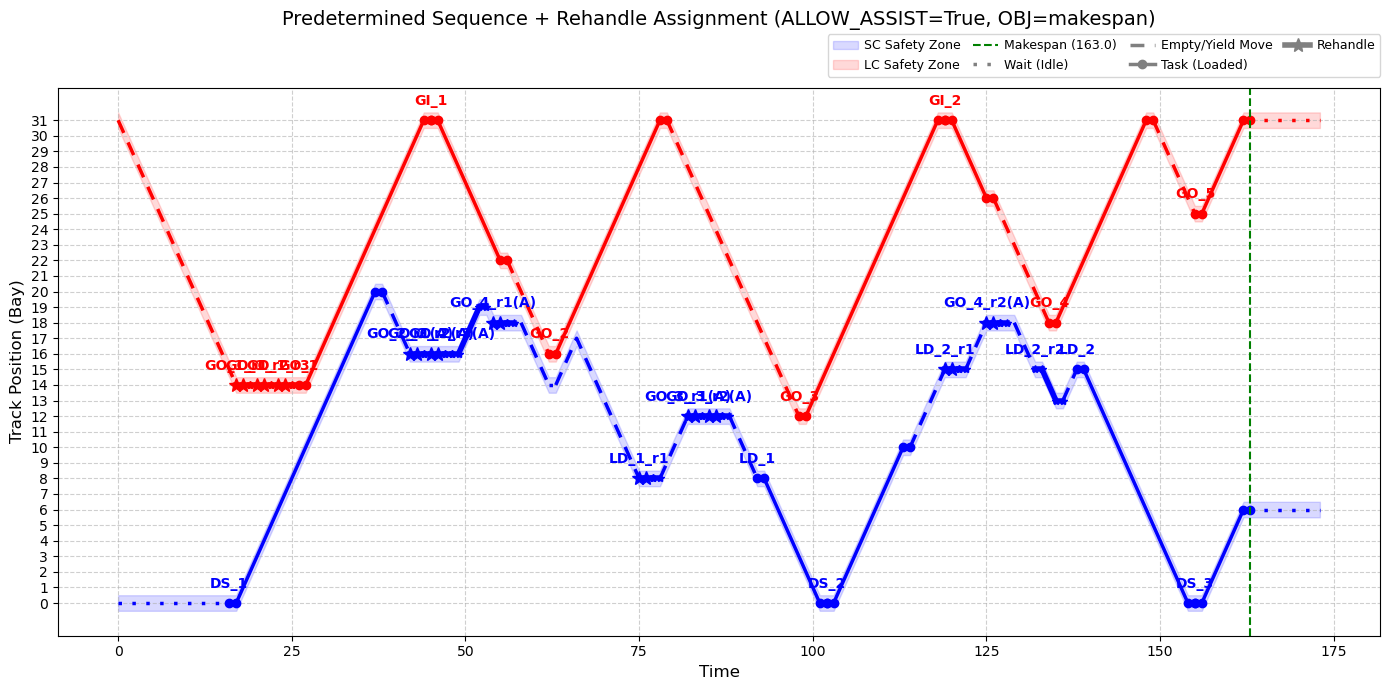

In [9]:
# =========================================================
# 9. Visualization (원본 시각화 코드 재사용)
#    굵은 선 + * = Rehandle,  라벨 (A) = 반대편 크레인이 지원한 Rehandle
# =========================================================
if model.SolCount > 0:
    import math
    import matplotlib.pyplot as plt
    import matplotlib.lines as mlines

    # =========================
    # Visualization
    # =========================
    plt.figure(figsize=(14, 7))
    crane_colors = {"SC": "blue", "LC": "red"}

    # 시간축은 정수 격자(1 단위). t_hat·pick·drop 이 소수(실데이터 초 단위 등)여도 되도록 반올림하고,
    # 빈 이동 속도는 1/t_hat bay per 시간 단위로 그린다.
    _r = lambda x: int(round(x))
    _pick = _r(pick)
    _vmax = 1.0 / t_hat
    max_t = int(math.ceil(makespan.X)) + 10
    time_arr = list(range(max_t + 1))
    ypos = {v: [float(crane_initial[v])] * (max_t + 1) for v in Set_V}
    state = {v: ['idle'] * (max_t + 1) for v in Set_V}

    sorted_cranes = sorted(Set_V, key=lambda v: crane_index[v])
    c_bottom = sorted_cranes[0]  
    c_top = sorted_cranes[1]     
    delta_val = delta[(c_bottom, c_top)]

    for v in Set_V:
        tasks = [r for r in result_rows if r["crane"] == v]
        for task in tasks:
            start_t = int(round(task["start"]))
            dur = int(round(task["duration"]))
            o_loc = task["origin"]
            d_loc = task["destination"]
            
            travel_time = _r(abs(o_loc - d_loc) * t_hat)
            rehandle_dur = _r(dur - (pick + drop + abs(o_loc - d_loc) * t_hat))
            
            curr_time = start_t
            
            if rehandle_dur > 0:
                for t in range(curr_time, curr_time + rehandle_dur):
                    if t <= max_t:
                        ypos[v][t] = float(o_loc)
                        state[v][t] = 'active'
                curr_time += rehandle_dur
                
            for t in range(curr_time, curr_time + _pick):
                if t <= max_t:
                    ypos[v][t] = float(o_loc)
                    state[v][t] = 'active'
            curr_time += _pick
            
            arr_time = curr_time + travel_time
            step = (d_loc - o_loc) / travel_time if travel_time > 0 else 0.0
            curr_y = float(o_loc)
            for t in range(curr_time, arr_time + 1):
                if t <= max_t:
                    ypos[v][t] = curr_y
                    state[v][t] = 'active'
                if t < arr_time: curr_y += step
            curr_time = arr_time
            
            for t in range(curr_time, start_t + dur + 1):
                if t <= max_t:
                    ypos[v][t] = float(d_loc)
                    state[v][t] = 'active'

    for v in Set_V:
        tasks = [r for r in result_rows if r["crane"] == v]
        if not tasks: continue
        
        first_start = int(round(tasks[0]["start"]))
        loc_first = tasks[0]["origin"]
        dist_first = _r(abs(crane_initial[v] - loc_first) * t_hat)
        move_start_first = first_start - dist_first
        
        curr_y = float(crane_initial[v])
        step = (loc_first - crane_initial[v]) / dist_first if dist_first > 0 else 0.0
        for t in range(max(0, move_start_first), first_start):
            if t <= max_t and state[v][t] == 'idle':
                ypos[v][t] = curr_y
                curr_y += step
                
        for t in range(0, max(0, move_start_first)):
            if t <= max_t and state[v][t] == 'idle': ypos[v][t] = float(crane_initial[v])

        for i in range(len(tasks)-1):
            end_prev = int(round(tasks[i]["completion"]))
            start_next = int(round(tasks[i+1]["start"]))
            loc_prev = tasks[i]["destination"]
            loc_next = tasks[i+1]["origin"]
            dist = _r(abs(loc_prev - loc_next) * t_hat)
            move_start = start_next - dist
            
            for t in range(end_prev, move_start):
                if t <= max_t and state[v][t] == 'idle': ypos[v][t] = float(loc_prev)
            
            curr_y = float(loc_prev)
            step = (loc_next - loc_prev) / dist if dist > 0 else 0.0
            for t in range(max(end_prev, move_start), start_next):
                if t <= max_t and state[v][t] == 'idle':
                    ypos[v][t] = curr_y
                    curr_y += step

        last_end = int(round(tasks[-1]["completion"]))
        loc_last = tasks[-1]["destination"]
        for t in range(last_end, max_t + 1):
            if state[v][t] == 'idle': ypos[v][t] = float(loc_last)

    for sweep in range(300):
        for t in range(max_t + 1):
            if ypos[c_bottom][t] > ypos[c_top][t] - delta_val: 
                if state[c_bottom][t] == 'active' and state[c_top][t] == 'idle':
                    ypos[c_top][t] = ypos[c_bottom][t] + delta_val
                elif state[c_top][t] == 'active' and state[c_bottom][t] == 'idle':
                    ypos[c_bottom][t] = ypos[c_top][t] - delta_val
                elif state[c_bottom][t] == 'idle' and state[c_top][t] == 'idle':
                    mid = (ypos[c_bottom][t] + ypos[c_top][t]) / 2.0
                    ypos[c_bottom][t] = mid - delta_val / 2.0
                    ypos[c_top][t] = mid + delta_val / 2.0
        
        for v in Set_V:
            for t in range(1, max_t + 1):
                if state[v][t] == 'idle':
                    if ypos[v][t] > ypos[v][t-1] + _vmax: ypos[v][t] = ypos[v][t-1] + _vmax
                    if ypos[v][t] < ypos[v][t-1] - _vmax: ypos[v][t] = ypos[v][t-1] - _vmax
            for t in range(max_t - 1, -1, -1):
                if state[v][t] == 'idle':
                    if ypos[v][t] > ypos[v][t+1] + _vmax: ypos[v][t] = ypos[v][t+1] + _vmax
                    if ypos[v][t] < ypos[v][t+1] - _vmax: ypos[v][t] = ypos[v][t+1] - _vmax
        
        for v in Set_V:
            ypos[v][0] = float(crane_initial[v])

    for v in Set_V:
        upper_bounds = [val + 0.5 for val in ypos[v]]
        lower_bounds = [val - 0.5 for val in ypos[v]]
        plt.fill_between(
            time_arr, lower_bounds, upper_bounds,
            color=crane_colors[v],
            alpha=0.15,
            label=f'{v} Safety Zone'
        )

        tasks = [r for r in result_rows if r["crane"] == v]
        for task in tasks:
            start_t = task["start"]
            dur = task["duration"]
            o_loc = task["origin"]
            d_loc = task["destination"]
            
            travel_time = abs(o_loc - d_loc) * t_hat
            rehandle_dur = dur - (pick + drop + travel_time)
            
            curr_time = start_t
            
            if rehandle_dur > 0:
                rehandle_end = curr_time + rehandle_dur
                plt.plot([curr_time, rehandle_end], [o_loc, o_loc], color=crane_colors[v], linestyle='-', linewidth=4.0, marker='*', markersize=10)
                curr_time = rehandle_end
                
            pick_end = curr_time + pick
            plt.plot([curr_time, pick_end], [o_loc, o_loc], color=crane_colors[v], linestyle='-', linewidth=(4.0 if task['task'] in Set_R else 2.5), marker=('*' if task['task'] in Set_R else 'o'))
            
            arr_time = pick_end + travel_time
            plt.plot([pick_end, arr_time], [o_loc, d_loc], color=crane_colors[v], linestyle='-', linewidth=(4.0 if task['task'] in Set_R else 2.5))
            
            finish_time = arr_time + drop
            plt.plot([arr_time, finish_time], [d_loc, d_loc], color=crane_colors[v], linestyle='-', linewidth=(4.0 if task['task'] in Set_R else 2.5), marker=('*' if task['task'] in Set_R else 'o'))

            task_label = str(task["task"]) + ("(A)" if task["assisted"] else "")
            plt.text(start_t, o_loc + 0.8, task_label, fontsize=10, color=crane_colors[v], fontweight='bold', ha='center', va='bottom')

        intervals = []
        for t in range(max_t):
            if state[v][t] == 'active' and state[v][t+1] == 'active':
                intervals.append('active')
            else:
                speed = abs(ypos[v][t+1] - ypos[v][t])
                intervals.append('empty' if speed > 0.01 else 'wait')

        start_t = 0
        while start_t < max_t:
            ctype = intervals[start_t]
            if ctype == 'active':
                start_t += 1
                continue
                
            end_t = start_t
            while end_t < max_t and intervals[end_t] == ctype:
                end_t += 1
                
            t_arr = list(range(start_t, end_t + 1))
            y_arr = [ypos[v][t] for t in t_arr]
            
            if ctype == 'empty':
                plt.plot(t_arr, y_arr, color=crane_colors[v], linestyle='--', dashes=(4, 3), linewidth=2.5)
            elif ctype == 'wait':
                plt.plot(t_arr, y_arr, color=crane_colors[v], linestyle=':', dashes=(1, 3), linewidth=2.5)
                
            start_t = end_t

    if makespan.X > 0:
        plt.axvline(x=makespan.X, color='green', linestyle='--', label=f'Makespan ({makespan.X:.1f})')

    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    
    wait_line = mlines.Line2D([], [], color='gray', linestyle=':', dashes=(1, 3), linewidth=2.5, label='Wait (Idle)')
    empty_line = mlines.Line2D([], [], color='gray', linestyle='--', dashes=(4, 3), linewidth=2.5, label='Empty/Yield Move')
    loaded_line = mlines.Line2D([], [], color='gray', linestyle='-', linewidth=2.5, marker='o', label='Task (Loaded)')
    rehandle_line = mlines.Line2D([], [], color='gray', linestyle='-', linewidth=4.0, marker='*', markersize=10, label='Rehandle')

    final_handles = list(by_label.values()) + [wait_line, empty_line, loaded_line, rehandle_line]
    final_labels = list(by_label.keys()) + ['Wait (Idle)', 'Empty/Yield Move', 'Task (Loaded)', 'Rehandle']

    plt.legend(final_handles, final_labels, loc='lower right', bbox_to_anchor=(1.0, 1.02), ncol=4, fontsize=9, columnspacing=1.0, handletextpad=0.5, borderaxespad=0.)
    plt.xlabel("Time", fontsize=12)
    plt.ylabel("Track Position (Bay)", fontsize=12)
    plt.title(f"Predetermined Sequence + Rehandle Assignment (ALLOW_ASSIST={ALLOW_ASSIST}, OBJ={OBJ})", fontsize=14, pad=45)
    plt.yticks(Bay) 
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()